In [11]:
import matplotlib.pyplot as plt
import h5py
import numpy as np
import pandas as pd
import re
import os
import sys

In [5]:
def load_events(filename, well_no = 0, recording_no = 0):
    with h5py.File(filename, "r") as h5_file:
        h5_object = h5_file['wells']['well{0:0>3}'.format(well_no)]['rec{0:0>4}'.format(recording_no)]
        events = h5_object['events']
        events_arr= np.array(events)
        events_dataset = pd.DataFrame(events_arr)
    
    events_dataset["frameno_adjusted"] = events_dataset["frameno"] - events_dataset.loc[0, "frameno"]
    events_dataset["eventmessage_decoded"] = events_dataset["eventmessage"].apply(lambda x: x.decode("utf8"))
    events_dataset.loc[1100, "eventmessage_decoded"]

    return events_dataset

In [6]:
filename = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/7-3_mouse_1d_test/mouse1d_test_well_2_18.raw.h5"
well = 2
events = load_events(filename, well)
events


,frameno,eventtype,eventid,eventmessage,frameno_adjusted,eventmessage_decoded
0,48910487,1,1,"b'{""before_training"":""1""}\n'",0,"{""before_training"":""1""}\n"
1,48910538,1,128,"b'{""start_stimulation"":""loc4_distance""}\n'",51,"{""start_stimulation"":""loc4_distance""}\n"
2,48921594,1,129,"b'{""end_stimulation"":""loc4_distance""}\n'",11107,"{""end_stimulation"":""loc4_distance""}\n"
3,48921748,1,128,"b'{""start_stimulation"":""loc4_distance""}\n'",11261,"{""start_stimulation"":""loc4_distance""}\n"
4,48932805,1,129,"b'{""end_stimulation"":""loc4_distance""}\n'",22318,"{""end_stimulation"":""loc4_distance""}\n"
...,...,...,...,...,...,...
1453,57877272,1,128,"b'{""start_stimulation"":""loc4_distance""}\n'",8966785,"{""start_stimulation"":""loc4_distance""}\n"
1454,57888328,1,129,"b'{""end_stimulation"":""loc4_distance""}\n'",8977841,"{""end_stimulation"":""loc4_distance""}\n"
1455,57888379,1,128,"b'{""start_stimulation"":""loc4_distance""}\n'",8977892,"{""start_stimulation"":""loc4_distance""}\n"
1456,57899435,1,129,"b'{""end_stimulation"":""loc4_distance""}\n'",8988948,"{""end_stimulation"":""loc4_distance""}\n"


In [29]:
pre_train_movement_df = pd.DataFrame(columns = ["frameno", "position"])
train_movement_df = pd.DataFrame(columns = ["frameno", "position"])
movement_df = pd.DataFrame(columns = ["frameno", "position"])

current_pos = -1

for i in events.index:
    
    message = events.loc[i, "eventmessage_decoded"]
    if "distance" in message:
        numbers = [int(num) for num in re.findall(r'\d+', message)]
        new_pos = numbers[0]
        
        if new_pos != current_pos:
            movement_df.loc[len(movement_df), :] = [events.loc[i, "frameno_adjusted"], new_pos]
            current_pos = new_pos
    elif message == "{\"training\":\"1\"}\n":
        print("switch to train")
        pre_train_movement_df = movement_df
        movement_df = pd.DataFrame(columns = ["frameno", "position"])


train_movement_df = movement_df
display(train_movement_df)
display(pre_train_movement_df)


switch to train


,frameno,position
0,3004498,2
1,3121159,1
2,3208710,2
3,3219289,1
4,3284501,2
...,...,...
82,8696639,6
83,8717796,7
84,8770874,6
85,8899834,5


,frameno,position
0,51,4
1,67011,3
2,243609,2
3,328585,3
4,505128,2
5,547565,1
6,670118,0
7,703489,7
8,830912,6
9,949297,5


In [35]:
def build_trainsition_df(movement_df: pd.DataFrame):
    num_locs = max(movement_df["position"]) + 1
    transition_df = pd.DataFrame(index = range(0, num_locs), columns = ["leftward", "rightward"], data = np.zeros((num_locs, 2)))
    
    current_pos = movement_df.loc[0, "position"]
    for i in movement_df.index[1:]:
        next_pos = movement_df.loc[i, "position"]
        if (next_pos + num_locs) % num_locs == (current_pos - 1 + num_locs) % num_locs:
            transition_df.loc[current_pos, "leftward"] += 1
        elif (next_pos + num_locs) % num_locs == (current_pos + 1 + num_locs) % num_locs:
            transition_df.loc[current_pos, "rightward"] += 1
        else:
            print("fail - next pos not one away from current_pos")
            print(next_pos)
            print(current_pos)
            sys.exit()

        current_pos = next_pos

    transition_df["total"] = transition_df["leftward"] + transition_df["rightward"]
    transition_df["proportion left"] = transition_df["leftward"]/transition_df["total"]

    return transition_df

In [38]:
train_transition_df = build_trainsition_df(train_movement_df)
pre_train_transition_df = build_trainsition_df(pre_train_movement_df)

(0.0, 1.0)

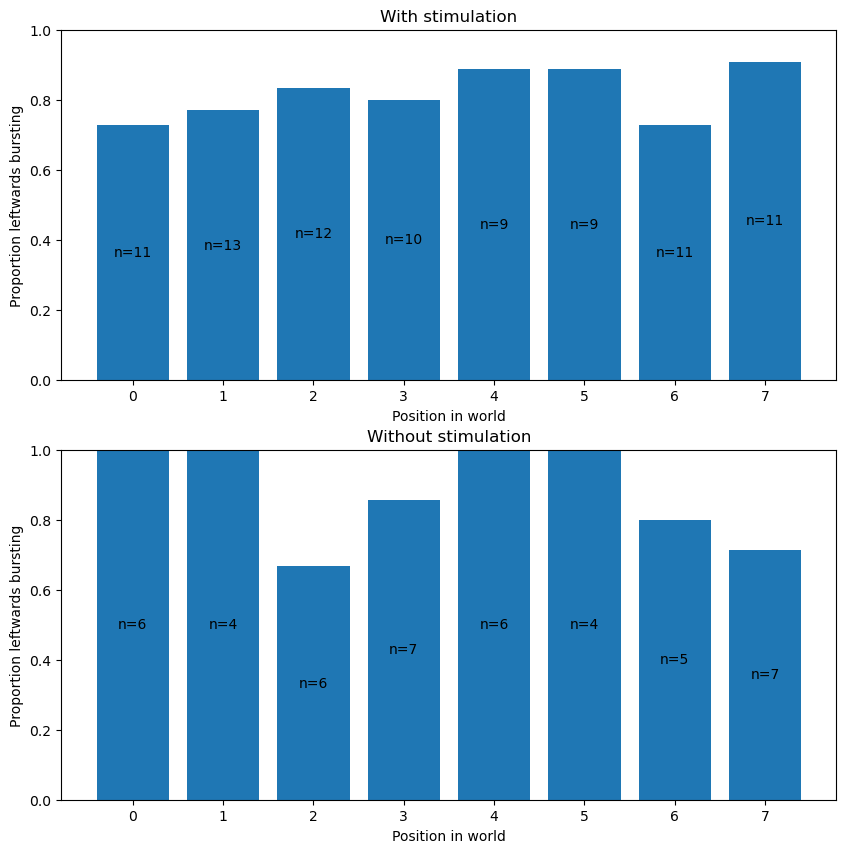

In [71]:
plt.figure(figsize = (10, 10))

ax = plt.subplot(211)
plt.title("With stimulation")
ax.bar(train_transition_df.index, train_transition_df["proportion left"])
ax.bar_label(ax.containers[0], labels = [f"n={i:.0f}" for i in train_transition_df["total"]], label_type='center')  # Annotating bars
plt.ylim(0, 1)
plt.ylabel("Proportion leftwards bursting")
plt.xlabel("Position in world")

ax = plt.subplot(212)
plt.title("Without stimulation")
ax.bar(pre_train_transition_df.index, pre_train_transition_df["proportion left"])
ax.bar_label(ax.containers[0], labels = [f"n={i:.0f}" for i in pre_train_transition_df["total"]], label_type = 'center')  # Annotating bars
plt.ylim(0, 1)
plt.ylabel("Proportion leftwards bursting")
plt.xlabel("Position in world")
plt.ylim(0, 1)